In [4]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/subway_ml_dataset.parquet")

ml_df = pd.read_parquet(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", ml_df.shape)
print("\nColumns:")
print(ml_df.columns.tolist())

display(ml_df.head())

Dataset loaded successfully!
Shape: (296114, 8)

Columns:
['service_date', 'a_station', 'b_station', 'route_ids', 'day_of_week', 'month', 'day_of_month', 'mean_seconds']


,service_date,a_station,b_station,route_ids,day_of_week,month,day_of_month,mean_seconds
0,2025-01-01,Van Cortlandt Park-242 St,238 St,1,2,1,1,97.30
1,2025-01-01,238 St,Van Cortlandt Park-242 St,1,2,1,1,174.16
2,2025-01-01,238 St,231 St,1,2,1,1,87.01
3,2025-01-01,231 St,Van Cortlandt Park-242 St,1,2,1,1,214.93
4,2025-01-01,231 St,238 St,1,2,1,1,128.88


In [2]:
# Ensure service_date is in datetime format
ml_df["service_date"] = pd.to_datetime(ml_df["service_date"])

# Sort data chronologically
ml_df = ml_df.sort_values("service_date").reset_index(drop=True)

# Train: January–September 2025
# Test: October–December 2025
split_date = pd.Timestamp("2025-10-01")

train_df = ml_df[ml_df["service_date"] < split_date].copy()
test_df = ml_df[ml_df["service_date"] >= split_date].copy()

print("Training period:")
print(train_df["service_date"].min(), "to", train_df["service_date"].max())

print("\nTesting period:")
print(test_df["service_date"].min(), "to", test_df["service_date"].max())

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining percentage:", round(len(train_df) / len(ml_df) * 100, 2), "%")
print("Testing percentage:", round(len(test_df) / len(ml_df) * 100, 2), "%")

Training period:
2025-01-01 00:00:00 to 2025-09-30 00:00:00

Testing period:
2025-10-01 00:00:00 to 2025-12-31 00:00:00

Training rows: 221284
Testing rows: 74830

Training percentage: 74.73 %
Testing percentage: 25.27 %


**Baseline**

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Target variable
y_train = train_df["mean_seconds"]
y_test = test_df["mean_seconds"]

# Baseline model
baseline_model = DummyRegressor(strategy="median")

# Train the baseline
baseline_model.fit(
    np.zeros((len(train_df), 1)),
    y_train
)

# Predict on test data
baseline_predictions = baseline_model.predict(
    np.zeros((len(test_df), 1))
)

# Evaluate
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("BASELINE MODEL RESULTS")
print("-" * 35)
print(f"MAE:  {baseline_mae:.2f} seconds")
print(f"RMSE: {baseline_rmse:.2f} seconds")
print(f"MAE in minutes: {baseline_mae / 60:.2f} minutes")

BASELINE MODEL RESULTS
-----------------------------------
MAE:  47.76 seconds
RMSE: 94.16 seconds
MAE in minutes: 0.80 minutes


In [6]:
# Features the model will use
feature_columns = [
    "a_station",
    "b_station",
    "route_ids",
    "day_of_week",
    "month",
    "day_of_month"
]

target_column = "mean_seconds"

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_train = train_df[target_column].copy()
y_test = test_df[target_column].copy()

# Identify categorical and numerical features
categorical_features = [
    "a_station",
    "b_station",
    "route_ids"
]

numerical_features = [
    "day_of_week",
    "month",
    "day_of_month"
]

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nCategorical features:", categorical_features)
print("Numerical features:", numerical_features)

print("\nMissing values in training features:")
print(X_train.isna().sum())

Training features shape: (221284, 6)
Testing features shape: (74830, 6)

Categorical features: ['a_station', 'b_station', 'route_ids']
Numerical features: ['day_of_week', 'month', 'day_of_month']

Missing values in training features:
a_station       0
b_station       0
route_ids       0
day_of_week     0
month           0
day_of_month    0
dtype: int64


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Convert categorical values into numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=10
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")
print("Categorical encoding: OneHotEncoder")
print("Unknown categories: ignored")
print("Rare categories: grouped when they occur fewer than 10 times")

Preprocessing pipeline created successfully!
Categorical encoding: OneHotEncoder
Unknown categories: ignored
Rare categories: grouped when they occur fewer than 10 times


In [8]:
import time
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create the complete ML pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the model
start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Model training completed in {training_time:.2f} seconds!")

Model training completed in 31.19 seconds!


In [9]:
# Predict travel times for the unseen test period
rf_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

# Compare against the baseline
improvement = (
    (baseline_mae - rf_mae) / baseline_mae
) * 100

print("RANDOM FOREST RESULTS")
print("-" * 40)
print(f"MAE:  {rf_mae:.2f} seconds")
print(f"RMSE: {rf_rmse:.2f} seconds")
print(f"MAE in minutes: {rf_mae / 60:.2f} minutes")

print("\nBASELINE COMPARISON")
print("-" * 40)
print(f"Baseline MAE: {baseline_mae:.2f} seconds")
print(f"Random Forest MAE: {rf_mae:.2f} seconds")
print(f"MAE improvement: {improvement:.2f}%")

RANDOM FOREST RESULTS
----------------------------------------
MAE:  39.53 seconds
RMSE: 58.86 seconds
MAE in minutes: 0.66 minutes

BASELINE COMPARISON
----------------------------------------
Baseline MAE: 47.76 seconds
Random Forest MAE: 39.53 seconds
MAE improvement: 17.23%


Prediction error summary (seconds):


count    74830.00
mean        -0.00
std         58.86
min       -494.54
25%        -35.00
50%        -17.72
75%         13.27
max        794.81
Name: error_seconds, dtype: float64


Largest absolute prediction errors:


C:\Users\Pradeep\AppData\Local\Temp\ipykernel_76476\2698996246.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,service_date,a_station,b_station,route_ids,actual_seconds,predicted_seconds,error_seconds,absolute_error_seconds
276010,2025-12-08,Cortelyou Rd,Kings Hwy,Q,922.54,127.73,794.81,794.81
251974,2025-11-06,125 St,Grand Central-42 St,6 6X,882.56,127.73,754.83,754.83
265743,2025-11-25,145 St,Tremont Av,D,799.93,127.73,672.20,672.20
240631,2025-10-23,40 St-Lowery St,Hunters Point Av,7,795.92,127.73,668.19,668.19
284473,2025-12-17,Dyckman St,Van Cortlandt Park-242 St,1,734.37,127.73,606.64,606.64
273469,2025-12-04,Kings Hwy,18 Av,F,693.04,127.73,565.31,565.31
221443,2025-10-01,145 St,Tremont Av,D,692.31,127.73,564.58,564.58
275913,2025-12-08,14 St,Broadway-Lafayette St,F,685.38,127.73,557.65,557.65
262854,2025-11-20,Pelham Bay Park,Parkchester,6,684.53,127.73,556.80,556.80
222601,2025-10-02,145 St,Tremont Av,D,662.92,127.73,535.19,535.19


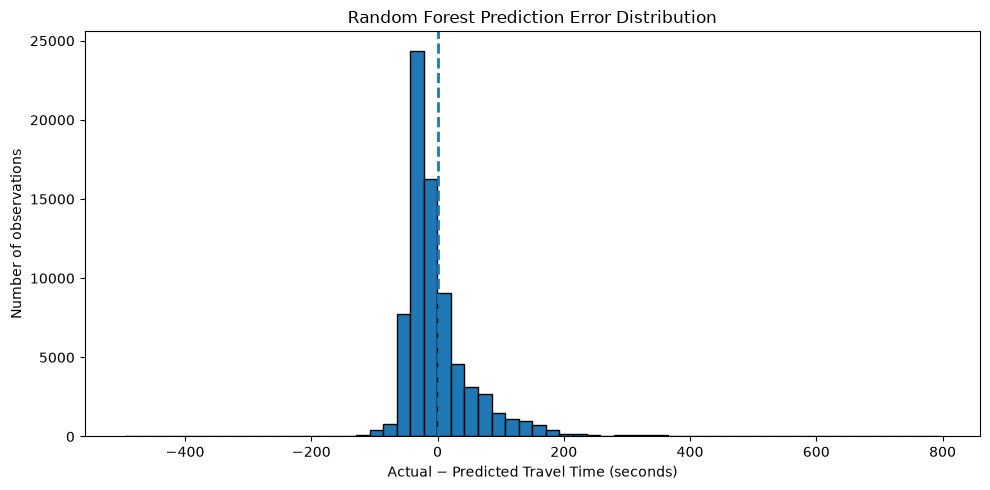

In [10]:
import matplotlib.pyplot as plt

# Build a table of actual and predicted values
results = test_df[
    ["service_date", "a_station", "b_station", "route_ids"]
].copy()

results["actual_seconds"] = y_test.to_numpy()
results["predicted_seconds"] = rf_predictions
results["error_seconds"] = (
    results["actual_seconds"] - results["predicted_seconds"]
)
results["absolute_error_seconds"] = results["error_seconds"].abs()

print("Prediction error summary (seconds):")
display(results["error_seconds"].describe().round(2))

print("\nLargest absolute prediction errors:")
display(
    results.nlargest(10, "absolute_error_seconds")[
        [
            "service_date",
            "a_station",
            "b_station",
            "route_ids",
            "actual_seconds",
            "predicted_seconds",
            "error_seconds",
            "absolute_error_seconds"
        ]
    ].round(2)
)

# Visualize the error distribution
plt.figure(figsize=(10, 5))
plt.hist(results["error_seconds"], bins=60, edgecolor="black")
plt.axvline(0, linestyle="--", linewidth=2)
plt.title("Random Forest Prediction Error Distribution")
plt.xlabel("Actual − Predicted Travel Time (seconds)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

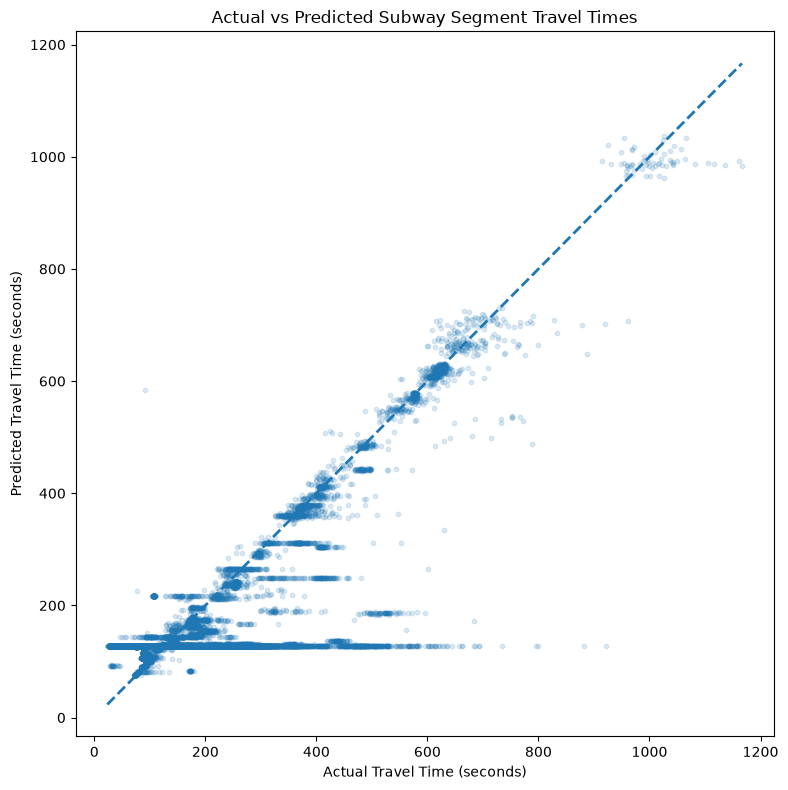

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.scatter(
    results["actual_seconds"],
    results["predicted_seconds"],
    alpha=0.15,
    s=10
)

# Perfect-prediction reference line
lower = min(
    results["actual_seconds"].min(),
    results["predicted_seconds"].min()
)
upper = max(
    results["actual_seconds"].max(),
    results["predicted_seconds"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=2
)

plt.title("Actual vs Predicted Subway Segment Travel Times")
plt.xlabel("Actual Travel Time (seconds)")
plt.ylabel("Predicted Travel Time (seconds)")
plt.tight_layout()
plt.show()

In [12]:
# Identify the observations with the largest prediction errors
worst_predictions = results.nlargest(
    15, "absolute_error_seconds"
).copy()

worst_predictions["actual_minutes"] = (
    worst_predictions["actual_seconds"] / 60
)

worst_predictions["predicted_minutes"] = (
    worst_predictions["predicted_seconds"] / 60
)

worst_predictions["absolute_error_minutes"] = (
    worst_predictions["absolute_error_seconds"] / 60
)

display(
    worst_predictions[
        [
            "service_date",
            "a_station",
            "b_station",
            "route_ids",
            "actual_minutes",
            "predicted_minutes",
            "absolute_error_minutes"
        ]
    ].round(2)
)

C:\Users\Pradeep\AppData\Local\Temp\ipykernel_76476\1745006229.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,service_date,a_station,b_station,route_ids,actual_minutes,predicted_minutes,absolute_error_minutes
276010,2025-12-08,Cortelyou Rd,Kings Hwy,Q,15.38,2.13,13.25
251974,2025-11-06,125 St,Grand Central-42 St,6 6X,14.71,2.13,12.58
265743,2025-11-25,145 St,Tremont Av,D,13.33,2.13,11.20
240631,2025-10-23,40 St-Lowery St,Hunters Point Av,7,13.27,2.13,11.14
284473,2025-12-17,Dyckman St,Van Cortlandt Park-242 St,1,12.24,2.13,10.11
273469,2025-12-04,Kings Hwy,18 Av,F,11.55,2.13,9.42
221443,2025-10-01,145 St,Tremont Av,D,11.54,2.13,9.41
275913,2025-12-08,14 St,Broadway-Lafayette St,F,11.42,2.13,9.29
262854,2025-11-20,Pelham Bay Park,Parkchester,6,11.41,2.13,9.28
222601,2025-10-02,145 St,Tremont Av,D,11.05,2.13,8.92


In [13]:
# Examine the training history of the 5 worst prediction errors
worst_segments = worst_predictions[
    ["a_station", "b_station", "route_ids"]
].head(5).drop_duplicates()

history = train_df.merge(
    worst_segments,
    on=["a_station", "b_station", "route_ids"],
    how="inner"
)

history_summary = (
    history.groupby(["a_station", "b_station", "route_ids"])
    .agg(
        training_records=("mean_seconds", "size"),
        training_median_minutes=("mean_seconds", lambda x: x.median() / 60),
        training_mean_minutes=("mean_seconds", lambda x: x.mean() / 60),
        training_max_minutes=("mean_seconds", lambda x: x.max() / 60),
        training_min_minutes=("mean_seconds", lambda x: x.min() / 60)
    )
    .round(2)
    .reset_index()
)

display(history_summary)

,a_station,b_station,route_ids,training_records,training_median_minutes,training_mean_minutes,training_max_minutes,training_min_minutes
0,145 St,Tremont Av,D,172,8.01,9.07,13.15,7.48
1,Dyckman St,Van Cortlandt Park-242 St,1,2,12.36,12.36,12.58,12.14


In [14]:
# Inspect actual vs predicted values for the two identified segments
segments_to_check = [
    ("145 St", "Tremont Av", "D"),
    ("Dyckman St", "Van Cortlandt Park-242 St", "1")
]

for a_station, b_station, route_id in segments_to_check:
    segment_results = results[
        (results["a_station"] == a_station)
        & (results["b_station"] == b_station)
        & (results["route_ids"] == route_id)
    ]

    print(f"\n{a_station} -> {b_station} ({route_id})")
    print("Test records:", len(segment_results))

    if not segment_results.empty:
        display(
            segment_results[
                [
                    "service_date",
                    "actual_seconds",
                    "predicted_seconds",
                    "error_seconds"
                ]
            ].round(2)
        )


145 St -> Tremont Av (D)
Test records: 58


C:\Users\Pradeep\AppData\Local\Temp\ipykernel_76476\1882320200.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,service_date,actual_seconds,predicted_seconds,error_seconds
221443,2025-10-01,692.31,127.73,564.58
222601,2025-10-02,662.92,127.73,535.19
223729,2025-10-03,476.29,127.73,348.56
224886,2025-10-06,472.93,127.73,345.20
228309,2025-10-09,473.46,127.73,345.73
229460,2025-10-10,473.21,127.73,345.48
230597,2025-10-13,472.57,127.73,344.84
231716,2025-10-14,479.80,127.73,352.07
232866,2025-10-15,467.57,127.73,339.84
234004,2025-10-16,488.73,127.73,361.00



Dyckman St -> Van Cortlandt Park-242 St (1)
Test records: 1


C:\Users\Pradeep\AppData\Local\Temp\ipykernel_76476\1882320200.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,service_date,actual_seconds,predicted_seconds,error_seconds
284473,2025-12-17,734.37,127.73,606.64


In [15]:
# Inspect how the preprocessing pipeline represents this station pair
sample = X_train[
    (X_train["a_station"] == "145 St")
    & (X_train["b_station"] == "Tremont Av")
    & (X_train["route_ids"] == "D")
].head(1)

print("Sample training row:")
display(sample)

# Find the one-hot encoded feature names
encoder = rf_model.named_steps["preprocessor"].named_transformers_["categorical"]
encoded_names = encoder.get_feature_names_out(categorical_features)

print("\nEncoded features containing the station names or route:")
print([
    name for name in encoded_names
    if "145 St" in name or "Tremont Av" in name or "route_ids_D" in name
][:30])

Sample training row:


,a_station,b_station,route_ids,day_of_week,month,day_of_month
1252,145 St,Tremont Av,D,3,1,2



Encoded features containing the station names or route:
['a_station_145 St', 'a_station_Tremont Av', 'a_station_West Farms Sq-E Tremont Av', 'a_station_Westchester Sq-E Tremont Av', 'b_station_145 St', 'b_station_Tremont Av', 'b_station_West Farms Sq-E Tremont Av', 'b_station_Westchester Sq-E Tremont Av', 'route_ids_D', 'route_ids_D E F', 'route_ids_D E F FX M', 'route_ids_D E F M', 'route_ids_D F', 'route_ids_D F FX', 'route_ids_D F FX M', 'route_ids_D F FX Q', 'route_ids_D F G', 'route_ids_D F M', 'route_ids_D F N', 'route_ids_D F N R', 'route_ids_D F N R W', 'route_ids_D F Q', 'route_ids_D F R', 'route_ids_D N', 'route_ids_D N Q', 'route_ids_D N Q R', 'route_ids_D N Q R W', 'route_ids_D N Q W', 'route_ids_D N R', 'route_ids_D N R W']


In [16]:
# Learn typical travel time for each station-direction-route segment
segment_medians = (
    train_df.groupby(
        ["a_station", "b_station", "route_ids"]
    )["mean_seconds"]
    .median()
)

global_median = train_df["mean_seconds"].median()

# Predict using the training median for each segment
segment_keys = pd.MultiIndex.from_frame(
    test_df[["a_station", "b_station", "route_ids"]]
)

segment_predictions = segment_medians.reindex(segment_keys).to_numpy()

# Fall back to global median for unseen segments
segment_predictions = np.where(
    pd.isna(segment_predictions),
    global_median,
    segment_predictions
)

segment_mae = mean_absolute_error(y_test, segment_predictions)
segment_rmse = np.sqrt(mean_squared_error(y_test, segment_predictions))

print("SEGMENT-MEDIAN BENCHMARK")
print("-" * 35)
print(f"MAE:  {segment_mae:.2f} seconds")
print(f"RMSE: {segment_rmse:.2f} seconds")

print("\nMODEL COMPARISON")
print(f"Global-median baseline MAE: {baseline_mae:.2f} seconds")
print(f"Random Forest MAE:          {rf_mae:.2f} seconds")
print(f"Segment-median MAE:         {segment_mae:.2f} seconds")

SEGMENT-MEDIAN BENCHMARK
-----------------------------------
MAE:  6.74 seconds
RMSE: 18.44 seconds

MODEL COMPARISON
Global-median baseline MAE: 47.76 seconds
Random Forest MAE:          39.53 seconds
Segment-median MAE:         6.74 seconds


In [17]:
# Identify which test observations have matching training history
known_segments = pd.MultiIndex.from_frame(
    train_df[["a_station", "b_station", "route_ids"]].drop_duplicates()
)

test_segments = pd.MultiIndex.from_frame(
    test_df[["a_station", "b_station", "route_ids"]]
)

has_history = test_segments.isin(known_segments)

print("Test observations:", len(test_df))
print("Observations with training history:", has_history.sum())
print("Observations without training history:", (~has_history).sum())
print(
    "History coverage:",
    f"{has_history.mean() * 100:.2f}%"
)

Test observations: 74830
Observations with training history: 74188
Observations without training history: 642
History coverage: 99.14%


In [18]:
# Evaluate prediction errors separately for known and unseen segments

known_mask = has_history

known_mae = mean_absolute_error(
    y_test[known_mask],
    segment_predictions[known_mask]
)

known_rmse = np.sqrt(mean_squared_error(
    y_test[known_mask],
    segment_predictions[known_mask]
))

unseen_mae = mean_absolute_error(
    y_test[~known_mask],
    segment_predictions[~known_mask]
)

unseen_rmse = np.sqrt(mean_squared_error(
    y_test[~known_mask],
    segment_predictions[~known_mask]
))

print("KNOWN SEGMENTS")
print(f"Observations: {known_mask.sum():,}")
print(f"MAE: {known_mae:.2f} seconds")
print(f"RMSE: {known_rmse:.2f} seconds")

print("\nUNSEEN SEGMENTS")
print(f"Observations: {(~known_mask).sum():,}")
print(f"MAE: {unseen_mae:.2f} seconds")
print(f"RMSE: {unseen_rmse:.2f} seconds")

KNOWN SEGMENTS
Observations: 74,188
MAE: 6.13 seconds
RMSE: 13.27 seconds

UNSEEN SEGMENTS
Observations: 642
MAE: 77.27 seconds
RMSE: 138.76 seconds


In [19]:
# Compare all models on the same test period

comparison = pd.DataFrame({
    "Model": [
        "Global Median Baseline",
        "Random Forest",
        "Historical Segment Median"
    ],
    "MAE (seconds)": [
        baseline_mae,
        rf_mae,
        segment_mae
    ],
    "RMSE (seconds)": [
        baseline_rmse,
        rf_rmse,
        segment_rmse
    ]
})

comparison["MAE (minutes)"] = comparison["MAE (seconds)"] / 60
comparison["RMSE (minutes)"] = comparison["RMSE (seconds)"] / 60

display(
    comparison.sort_values("MAE (seconds)").round(2)
)

,Model,MAE (seconds),RMSE (seconds),MAE (minutes),RMSE (minutes)
2,Historical Segment Median,6.74,18.44,0.11,0.31
1,Random Forest,39.53,58.86,0.66,0.98
0,Global Median Baseline,47.76,94.16,0.80,1.57


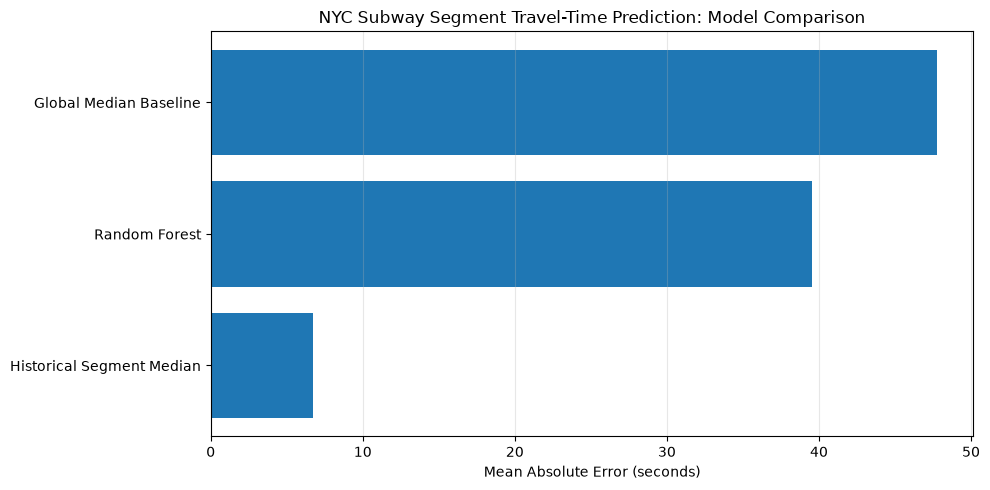

Chart saved to: C:\Users\Pradeep\OneDrive\Desktop\projects\NYC-Subway-Analytics\visuals\model_comparison.png


In [20]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create folder for saved charts
VISUALS_DIR = Path("../visuals")
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

# Compare MAE across models
plot_df = comparison.sort_values("MAE (seconds)")

plt.figure(figsize=(10, 5))
plt.barh(plot_df["Model"], plot_df["MAE (seconds)"])
plt.xlabel("Mean Absolute Error (seconds)")
plt.title("NYC Subway Segment Travel-Time Prediction: Model Comparison")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

chart_path = VISUALS_DIR / "model_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path.resolve())

In [21]:
from pathlib import Path

# Create output folder
RESULTS_DIR = Path("../reports")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save model comparison
comparison_path = RESULTS_DIR / "model_comparison.csv"
comparison.to_csv(comparison_path, index=False)

# Save test predictions for later analysis
prediction_results = test_df[
    ["service_date", "a_station", "b_station", "route_ids", "mean_seconds"]
].copy()

prediction_results = prediction_results.rename(
    columns={"mean_seconds": "actual_seconds"}
)

prediction_results["baseline_prediction"] = baseline_predictions
prediction_results["random_forest_prediction"] = rf_predictions
prediction_results["segment_median_prediction"] = segment_predictions

prediction_results["segment_median_absolute_error"] = (
    prediction_results["actual_seconds"]
    - prediction_results["segment_median_prediction"]
).abs()

predictions_path = RESULTS_DIR / "test_predictions.csv"
prediction_results.to_csv(predictions_path, index=False)

print("Saved model comparison:", comparison_path.resolve())
print("Saved test predictions:", predictions_path.resolve())
print("Prediction rows:", len(prediction_results))

Saved model comparison: C:\Users\Pradeep\OneDrive\Desktop\projects\NYC-Subway-Analytics\reports\model_comparison.csv
Saved test predictions: C:\Users\Pradeep\OneDrive\Desktop\projects\NYC-Subway-Analytics\reports\test_predictions.csv
Prediction rows: 74830
